In [42]:
import pandas as pd
import numpy as np

In [43]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
data = pd.read_csv(url)
data.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


### **Подготовка данных.**

In [44]:
data.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [45]:
#заполним пропуски
categorical = data.select_dtypes(include=['object', 'str']).columns
data[categorical] = data[categorical].fillna('NA')

numeric = data.select_dtypes(include='number').columns
data[numeric] = data[numeric].fillna(0.0)

In [46]:
data.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

### **Разделение данных.**

In [47]:
from sklearn.model_selection import train_test_split

In [48]:
df_full_train, df_test = train_test_split(data, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

#### **Вопрос 1.**

_Оценим важность числовых признаков с помощью ROC AUC._

In [49]:
from sklearn.metrics import roc_auc_score

In [50]:
#признаки для проверки
features = [
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count',
    'annual_income'
]

#таргет
y = df_train['converted']

#проверка
for col in features:
    auc = roc_auc_score(y, df_train[col])
    print(col, auc)

lead_score 0.7882254810906102
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
annual_income 0.6081977776250831


#### **Вопрос 2.**

_Обучение логистической регрессии и оценка ROC AUC модели._

In [51]:
#определим таргет
y_train = df_train['converted']
y_val = df_val['converted']

X_train = df_train.drop(columns=['converted'])
X_val = df_val.drop(columns=['converted'])

_Преобразуем категориальные признаки._

In [52]:
from sklearn.feature_extraction import DictVectorizer

In [53]:
dv = DictVectorizer(sparse=False)

#тренировочные
train_dicts = X_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

#валидационные
val_dicts = X_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

_Обучение логистической регресии._

In [54]:
from sklearn.linear_model import LogisticRegression

In [55]:
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [56]:
#получим вероятности принадлежности
#к положительому классу
y_pred = model.predict_proba(X_val)[:, 1]

In [57]:
#Считаем AUC на валидационной выборке
auc = roc_auc_score(y_val, y_pred)
round(auc, 3)

0.732

#### **Вопрос 3.**

_Precision и Recall: зависимость метрик от порога классификации Хотим найти порог, при котором обе метрики ближе всего друг к другу._

In [58]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

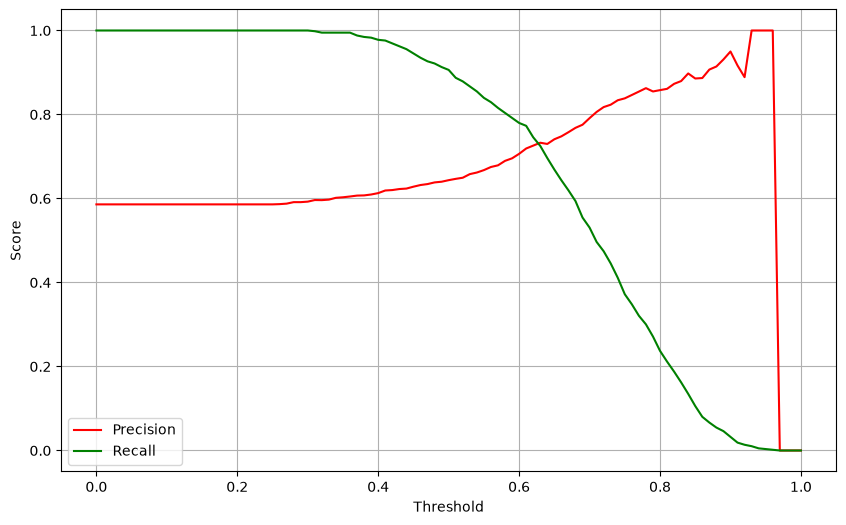

Лучший threshold: 0.63
Precision: 0.7327586206896551
Recall: 0.7252559726962458


In [59]:
#вероятность принадлежности к положительному классу
y_pred_proba = model.predict_proba(X_val)[:, 1]

#перебираем разные пороги
thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []

for t in thresholds:
    #предсказание полож или отриц 0-1
    y_pred = (y_pred_proba >= t).astype(int)

    #рассчет
    #zero_division=0, возвр ноль если
    #предсказание невозможно рассчитать
    precisions.append(precision_score(y_val, y_pred, zero_division=0))
    recalls.append(recall_score(y_val, y_pred, zero_division=0))

#график
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions, label='Precision', color='red')
plt.plot(thresholds, recalls, label='Recall', color='green')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid()
plt.show()

#преваратим в нумпай массивы
precisions = np.array(precisions)
recalls = np.array(recalls)

#нам не нужные случаи, когда оба равны нулю
valid = (precisions != 0) | (recalls != 0)
#разница
differences = np.abs(precisions - recalls)
#уберем неподходящие случаи
differences[~valid] = np.inf
#найдем минимальную разницу
best_threshold = thresholds[np.argmin(differences)]

print('Лучший threshold:', best_threshold)
print('Precision:', precisions[np.argmin(differences)])
print('Recall:', recalls[np.argmin(differences)])

#### **Вопрос 4.**

_F1 score: поиск порога с максимальным F1._

$$F1 = \frac{2 \cdot P \cdot R}{P + R}$$
_Это гармоническое среднее Precision и Recall. Оно сильнее штрафует ситуацию, когда одна метрика высокая, а другая низкая._

In [19]:
#вероятность принадлежности к положительному классу
y_pred_proba = model.predict_proba(X_val)[:, 1]

#разные значения порога
thresholds = np.arange(0.0, 1.01, 0.01)
f1_scores = []

for t in thresholds:
    y_pred = (y_pred_proba >= t).astype(int)

    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred, zero_division=0)

    #рассчет f1
    if precision + recall == 0:
        f1 = 0
    else:
        f1 = 2 * precision * recall / (precision + recall)

    f1_scores.append(f1)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print('Лучший threshold:', best_threshold)
print('Максимальный F1:', best_f1)

Лучший threshold: 0.41000000000000003
Максимальный F1: 0.7576158940397352


#### **Вопрос 5.**

_Проверим, насколько стабильно модель работает на разных частях обучающих данных._

In [20]:
from sklearn.model_selection import KFold

In [21]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

#в основной обучающей выборке будем выделять
#трейн и валидацию
for train_idx, val_idx in kfold.split(df_full_train):
    #делим данные
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    #обозначаем таргет
    y_train = df_train['converted'].values
    y_val = df_val['converted'].values

    #удаляем таргет
    del df_train['converted']
    del df_val['converted']

    #переведем столбцы в словари
    train_dicts = df_train.to_dict(orient='records')
    val_dicts = df_val.to_dict(orient='records')

    #проведем кодирование признаков
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_dicts)
    X_val = dv.transform(val_dicts)

    #обучим модель
    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )

    model.fit(X_train, y_train)

    #узнаем вероятность принадлежности
    #к положительному классу
    y_pred = model.predict_proba(X_val)[:, 1]

    #узнаем качество
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print('AUC результаты:', scores)
print('Среднее AUC:', np.mean(scores))
print('Стандартное отклонение:', np.std(scores))

AUC результаты: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Среднее AUC: 0.7317269710972524
Стандартное отклонение: 0.006853233151022138


#### **Вопрос 6.**

_Проверим, как меняется качество модели при разных значениях параметра регулиризации._

In [22]:
C_values = [0.000001, 0.001, 1]

#для каждого значения регуляризации
for C in C_values:
    scores = []
    #на пяти фолдах
    for train_idx, val_idx in kfold.split(df_full_train):
        #создадим выборки
        df_train = df_full_train.iloc[train_idx].copy()
        df_val = df_full_train.iloc[val_idx].copy()

        #таргет
        y_train = df_train['converted'].values
        y_val = df_val['converted'].values

        #удалить таргет
        del df_train['converted']
        del df_val['converted']

        #заново закодировать
        train_dicts = df_train.to_dict(orient='records')
        val_dicts = df_val.to_dict(orient='records')
        #
        dv = DictVectorizer(sparse=False)
        #
        X_train = dv.fit_transform(train_dicts)
        X_val = dv.transform(val_dicts)
        #обучить
        model = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )
        #
        model.fit(X_train, y_train)
        #узнать результат
        y_pred = model.predict_proba(X_val)[:, 1]
        #записать для каждого фолда
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
    #среднее для каждого фолда
    mean_auc = np.mean(scores)
    std_auc = np.std(scores)

    print(f'C = {C}: Среднее AUC = {mean_auc:.3f}, Std = {std_auc:.3f}')

C = 1e-06: Mean AUC = 0.617, Std = 0.019
C = 0.001: Mean AUC = 0.749, Std = 0.010
C = 1: Mean AUC = 0.732, Std = 0.007
